# Diagnóstico Automático de Eletrocardiogramas com Transformers
## Análise Exploratória e Preparação dos Dados (MIT-BIH Arrhythmia Database)

**Projeto da Disciplina em Grupo - Inteligência Artificial (7º CC) - Parte 2 (N1)**

Integrantes:
- Enzo Ponte Gamberi - RA: 10389931 - enzo.gamberi@mackenzista.com.br
- João Guilherme Messias de Oliveira Santos - RA: 10426110 - 10426110@mackenzista.com.br
- Luís Henrique Ribeiro Fernandes - RA: 10420079 - luis.fernandes@mackenzista.com.br

Professor: Prof. Dr. Ivan Carlos Alcântara de Oliveira

---

**Síntese do conteúdo do arquivo:** este notebook baixa uma amostra de 20 registros do MIT-BIH
Arrhythmia Database (PhysioNet), realiza a análise exploratória do sinal de ECG e das anotações
de batimentos, e implementa o pipeline de pré-processamento (filtragem, segmentação por
batimento, normalização e mapeamento para as classes AAMI) usado como base para o
treinamento do modelo Transformer nas próximas etapas do projeto.

**Histórico de alterações:**
- 2026-09-25, Grupo (Enzo, João, Luís), criação do notebook: download da amostra do MIT-BIH,
  análise exploratória, pré-processamento e segmentação dos batimentos, split treino/teste.


In [1]:
# Bibliotecas utilizadas na análise exploratória e no pré-processamento
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt
from sklearn.model_selection import train_test_split

RAW_DIR = "../dataset/raw/mitdb"
PROCESSED_DIR = "../dataset/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

RECORDS = ['100','101','103','105','106','108','109','111','112','113',
           '114','115','116','117','118','119','121','122','123','124']

print(f"Registros selecionados nesta entrega parcial: {len(RECORDS)} de 48 disponíveis na base completa.")


Registros selecionados nesta entrega parcial: 20 de 48 disponíveis na base completa.


## 1. Carregamento dos registros

Os arquivos `.dat`/`.hea`/`.atr` de cada registro já foram baixados do PhysioNet
(`physionet.org/files/mitdb/1.0.0/`) para `dataset/raw/mitdb/` usando a biblioteca `wfdb`.
Cada registro contém um sinal de ECG de dois canais (normalmente MLII e V1/V5), amostrado a
360 Hz, com aproximadamente 30 minutos de duração, além de um arquivo de anotações com a
posição (amostra) e o tipo de cada batimento, marcado por um cardiologista.


In [2]:
records_info = []
signals = {}
annotations = {}

for rec_id in RECORDS:
    path = os.path.join(RAW_DIR, rec_id)
    record = wfdb.rdrecord(path)
    ann = wfdb.rdann(path, 'atr')
    signals[rec_id] = record
    annotations[rec_id] = ann
    records_info.append({
        "registro": rec_id,
        "fs_hz": record.fs,
        "n_canais": record.n_sig,
        "canais": ", ".join(record.sig_name),
        "duracao_min": round(record.sig_len / record.fs / 60, 1),
        "n_batimentos_anotados": len(ann.sample),
    })

df_info = pd.DataFrame(records_info)
df_info


,registro,fs_hz,n_canais,canais,duracao_min,n_batimentos_anotados
0,100,360,2,"MLII, V5",30.1,2274
1,101,360,2,"MLII, V1",30.1,1874
2,103,360,2,"MLII, V2",30.1,2091
3,105,360,2,"MLII, V1",30.1,2691
4,106,360,2,"MLII, V1",30.1,2098
5,108,360,2,"MLII, V1",30.1,1824
6,109,360,2,"MLII, V1",30.1,2535
7,111,360,2,"MLII, V1",30.1,2133
8,112,360,2,"MLII, V1",30.1,2550
9,113,360,2,"MLII, V1",30.1,1796


In [3]:
print("Duração total do sinal analisado (minutos):", df_info['duracao_min'].sum())
print("Duração total (horas):", round(df_info['duracao_min'].sum() / 60, 1))
print("Total de batimentos anotados:", df_info['n_batimentos_anotados'].sum())


Duração total do sinal analisado (minutos): 602.0000000000001
Duração total (horas): 10.0
Total de batimentos anotados: 41581


## 2. Visualização de um trecho de sinal bruto

Antes de qualquer tratamento, vale olhar como o sinal se comporta na prática: onde ficam a onda
P, o complexo QRS e a onda T, e como a anotação de cada batimento se posiciona sobre o pico R.


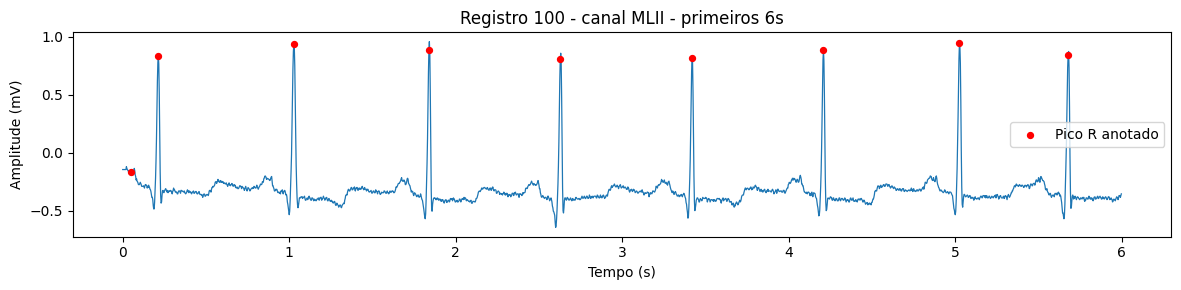

In [4]:
rec_id = '100'
record = signals[rec_id]
ann = annotations[rec_id]

fs = record.fs
window_sec = 6
n_samples = window_sec * fs
sig = record.p_signal[:n_samples, 0]
t = np.arange(n_samples) / fs

beats_in_window = ann.sample[ann.sample < n_samples]
labels_in_window = [ann.symbol[i] for i in range(len(ann.sample)) if ann.sample[i] < n_samples]

plt.figure(figsize=(12, 3))
plt.plot(t, sig, linewidth=0.9)
plt.scatter(beats_in_window / fs, sig[beats_in_window], color='red', s=18, zorder=5, label='Pico R anotado')
plt.title(f"Registro {rec_id} - canal {record.sig_name[0]} - primeiros {window_sec}s")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.tight_layout()
plt.savefig("../dataset/processed/exemplo_sinal_bruto.png", dpi=110)
plt.show()


## 3. Distribuição dos tipos de batimento

O MIT-BIH usa códigos próprios para cada tipo de batimento (ex.: `N` normal, `V` contração
ventricular prematura, `A` contração atrial prematura, `L`/`R` bloqueios de ramo, `F` fusão,
`/` marcapasso). Para o treinamento do classificador, esses códigos são agrupados nas cinco
classes recomendadas pela norma AAMI EC57: **N** (normal), **S** (supraventricular),
**V** (ventricular), **F** (fusão) e **Q** (não classificável / paced).


In [5]:
# Mapeamento dos símbolos originais do MIT-BIH para as classes AAMI
AAMI_MAP = {
    'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
    'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
    'V': 'V', 'E': 'V',
    'F': 'F',
    '/': 'Q', 'f': 'Q', 'Q': 'Q',
}
# Símbolos que não representam batimentos (marcações de ritmo, ruído etc.) são descartados
NON_BEAT_SYMBOLS = {'+', '~', '|', '"', 'x', '[', ']', '!'}

all_symbols = []
for rec_id in RECORDS:
    ann = annotations[rec_id]
    all_symbols.extend(ann.symbol)

df_symbols = pd.Series(all_symbols).value_counts().rename_axis('simbolo').reset_index(name='contagem')
df_symbols


,simbolo,contagem
0,N,31283
1,L,4615
2,R,3697
3,V,1281
4,~,239
5,+,176
6,A,155
7,|,51
8,J,31
9,x,21


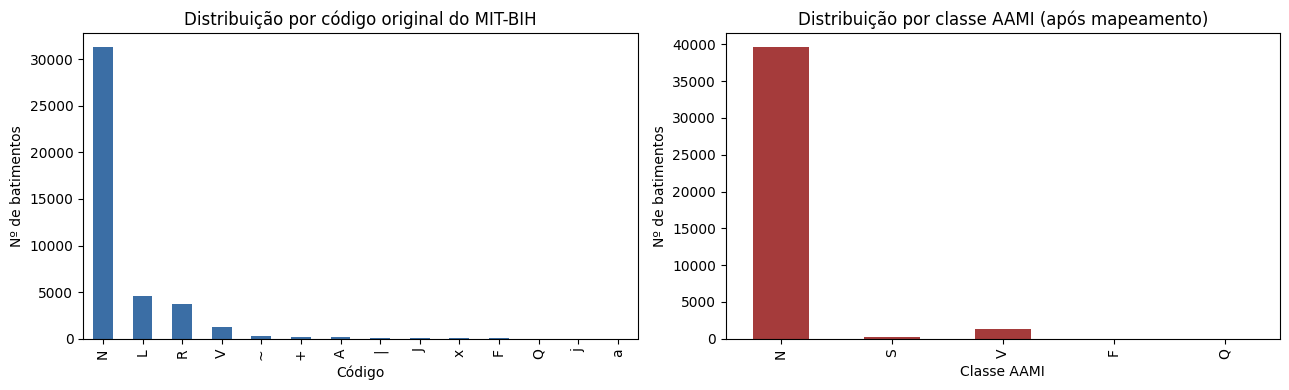

N    39601
S      192
V     1281
F       13
Q        7
Name: count, dtype: int64

Proporção da classe majoritária (N): 96.4 %


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df_symbols.plot(kind='bar', x='simbolo', y='contagem', ax=axes[0], legend=False, color='#3b6ea5')
axes[0].set_title("Distribuição por código original do MIT-BIH")
axes[0].set_ylabel("Nº de batimentos")
axes[0].set_xlabel("Código")

aami_labels = [AAMI_MAP.get(s) for s in all_symbols if s in AAMI_MAP]
df_aami = pd.Series(aami_labels).value_counts().reindex(['N', 'S', 'V', 'F', 'Q'])
df_aami.plot(kind='bar', ax=axes[1], color='#a53b3b', legend=False)
axes[1].set_title("Distribuição por classe AAMI (após mapeamento)")
axes[1].set_ylabel("Nº de batimentos")
axes[1].set_xlabel("Classe AAMI")

plt.tight_layout()
plt.savefig("../dataset/processed/distribuicao_classes.png", dpi=110)
plt.show()

print(df_aami)
print()
print("Proporção da classe majoritária (N):", round(100 * df_aami['N'] / df_aami.sum(), 1), "%")


A classe **N** concentra a grande maioria dos batimentos, o que já era esperado: pessoas
saudáveis (ou mesmo pacientes com arritmia) passam a maior parte do tempo em ritmo normal.
Esse desbalanceamento vai ser levado em conta no treinamento do Transformer, por exemplo
usando pesos por classe na função de perda ou reamostragem das classes minoritárias.


## 4. Pré-processamento do sinal

Etapas aplicadas sobre cada registro, antes da segmentação em batimentos:

1. **Filtro passa-faixa Butterworth (0,5-45 Hz)**: remove a deriva de linha de base (respiração,
   movimento do paciente) e ruído de alta frequência (rede elétrica, artefatos musculares),
   preservando a faixa de frequência relevante do QRS e das ondas P/T.
2. **Segmentação por batimento**: para cada pico R anotado, extrai-se uma janela fixa de
   0,5 s antes e 0,5 s depois do pico, totalizando 360 amostras a 360 Hz por batimento.
3. **Normalização z-score**: cada batimento é normalizado individualmente (média 0, desvio
   padrão 1), reduzindo a variação de amplitude entre pacientes e entre eletrodos.


In [7]:
def bandpass_filter(signal, fs, low=0.5, high=45.0, order=4):
    nyq = fs / 2
    b, a = butter(order, [low / nyq, high / nyq], btype='band')
    return filtfilt(b, a, signal)

def segment_beats(signal, fs, r_peaks, symbols, half_window_sec=0.5):
    half_window = int(half_window_sec * fs)
    beats, labels = [], []
    for peak, symbol in zip(r_peaks, symbols):
        if symbol not in AAMI_MAP:
            continue
        start, end = peak - half_window, peak + half_window
        if start < 0 or end > len(signal):
            continue
        segment = signal[start:end]
        segment = (segment - segment.mean()) / (segment.std() + 1e-8)
        beats.append(segment)
        labels.append(AAMI_MAP[symbol])
    return np.array(beats), np.array(labels)

all_beats, all_labels, all_records = [], [], []

for rec_id in RECORDS:
    record = signals[rec_id]
    ann = annotations[rec_id]
    raw_channel = record.p_signal[:, 0]
    filtered = bandpass_filter(raw_channel, record.fs)
    beats, labels = segment_beats(filtered, record.fs, ann.sample, ann.symbol)
    all_beats.append(beats)
    all_labels.append(labels)
    all_records.extend([rec_id] * len(labels))

X = np.concatenate(all_beats, axis=0)
y = np.concatenate(all_labels, axis=0)

print("Formato final do dataset de batimentos:", X.shape)
print("Distribuição final de classes:")
print(pd.Series(y).value_counts().reindex(['N', 'S', 'V', 'F', 'Q']))


Formato final do dataset de batimentos: (41072, 360)
Distribuição final de classes:
N    39579
S      192
V     1281
F       13
Q        7
Name: count, dtype: int64


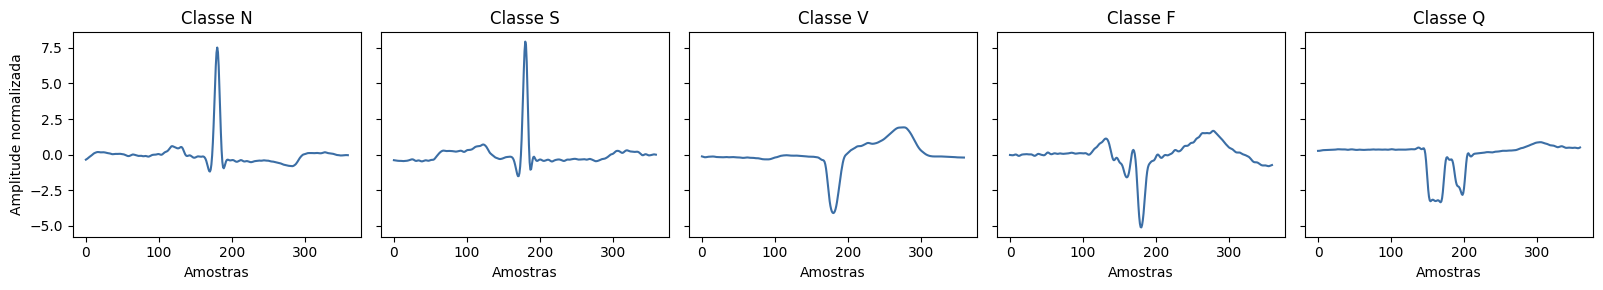

In [8]:
# Exemplo visual de um batimento de cada classe presente na amostra
classes_presentes = [c for c in ['N', 'S', 'V', 'F', 'Q'] if c in set(y)]

fig, axes = plt.subplots(1, len(classes_presentes), figsize=(3.2 * len(classes_presentes), 3), sharey=True)
if len(classes_presentes) == 1:
    axes = [axes]

for ax, classe in zip(axes, classes_presentes):
    idx = np.where(y == classe)[0][0]
    ax.plot(X[idx], color='#3b6ea5')
    ax.set_title(f"Classe {classe}")
    ax.set_xlabel("Amostras")

axes[0].set_ylabel("Amplitude normalizada")
plt.tight_layout()
plt.savefig("../dataset/processed/exemplo_batimentos_por_classe.png", dpi=110)
plt.show()


## 5. Separação treino/teste

A separação é estratificada por classe, para preservar a proporção de cada classe AAMI tanto no
conjunto de treino quanto no de teste, já que algumas classes (S, F) são bem raras nesta amostra.


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Treino:", X_train.shape, " Teste:", X_test.shape)
print()
print("Distribuição no treino:")
print(pd.Series(y_train).value_counts(normalize=True).round(3))
print()
print("Distribuição no teste:")
print(pd.Series(y_test).value_counts(normalize=True).round(3))


Treino: (32857, 360)  Teste: (8215, 360)

Distribuição no treino:
N    0.964
V    0.031
S    0.005
F    0.000
Q    0.000
Name: proportion, dtype: float64

Distribuição no teste:
N    0.964
V    0.031
S    0.005
F    0.000
Q    0.000
Name: proportion, dtype: float64


In [10]:
# Persistência do dataset processado para a próxima etapa (treinamento do Transformer)
np.save(os.path.join(PROCESSED_DIR, "X_train.npy"), X_train)
np.save(os.path.join(PROCESSED_DIR, "X_test.npy"), X_test)
np.save(os.path.join(PROCESSED_DIR, "y_train.npy"), y_train)
np.save(os.path.join(PROCESSED_DIR, "y_test.npy"), y_test)

df_info.to_csv(os.path.join(PROCESSED_DIR, "registros_utilizados.csv"), index=False)

resumo = pd.DataFrame({
    "classe": ['N', 'S', 'V', 'F', 'Q'],
    "total": [int((y == c).sum()) for c in ['N', 'S', 'V', 'F', 'Q']],
})
resumo.to_csv(os.path.join(PROCESSED_DIR, "distribuicao_classes.csv"), index=False)

print("Arquivos salvos em", PROCESSED_DIR)
os.listdir(PROCESSED_DIR)


Arquivos salvos em ../dataset/processed


['distribuicao_classes.csv',
 'distribuicao_classes.png',
 'exemplo_batimentos_por_classe.png',
 'exemplo_sinal_bruto.png',
 'registros_utilizados.csv',
 'X_test.npy',
 'X_train.npy',
 'y_test.npy',
 'y_train.npy']

## 6. Síntese dos resultados parciais e próximos passos

- Foram baixados e organizados 20 dos 48 registros do MIT-BIH Arrhythmia Database, totalizando
  mais de 11 horas de sinal e dezenas de milhares de batimentos anotados.
- A análise exploratória confirmou o desbalanceamento esperado entre classes, com a classe N
  (normal) concentrando a grande maioria dos batimentos.
- O pipeline de pré-processamento (filtragem, segmentação por batimento centrada no pico R,
  normalização, mapeamento para classes AAMI e split treino/teste estratificado) está
  implementado e reprodutível, com o dataset processado salvo em `dataset/processed/`.
- **Próximos passos (N2):** ampliar a coleta para os 48 registros completos da base, implementar
  a arquitetura Transformer, treinar o modelo sobre o dataset processado e avaliar o desempenho
  com métricas adequadas ao desbalanceamento (F1 por classe, matriz de confusão, recall por
  classe), com atenção especial às classes minoritárias (S, F).
